# Basic usage

Notebook for reproducing the basic usage case study in the paper GRASS as a Geocomputational Engine. 
It demonstrates how to setup GRASS, generate fractal terrain, classify landforms, and plot maps.

## Setup GRASS

Start a GRASS session in a new project with a Cartesian (XY) coordinate system.

In [6]:
# Import modules
import sys
import subprocess
from pathlib import Path

# Find GRASS Python packages
sys.path.append(
  subprocess.check_output(
    ["grass", "--config", "python_path"],
    text=True
    ).strip()
  )

# Import packages
import numpy as np
import grass.script as gs
import grass.jupyter as gj
from grass.tools import Tools

# Initialize GRASS session
gs.create_project("basics", overwrite=True)
gj.init("basics")
tools = Tools()

## Set region

Use [g.region](https://grass.osgeo.org/grass-stable/manuals/g.region.html) to set the extent and resolution of the computational region. Create a region starting at the origin and extending two hundred units north and eight hundred units east.

In [7]:
# Set computational region
tools.g_region(s=0, w=0, n=200, e=800, res=1)

## Generate fractal terrain

Generate a fractal terrain with [r.surf.fractal](https://grass.osgeo.org/grass-stable/manuals/r.surf.fractal.html). For reproducible results set a seed. Return the result as a NumPy array and take the absolute value with [np.abs](https://numpy.org/doc/2.5/reference/generated/numpy.absolute.html) to model river valleys.

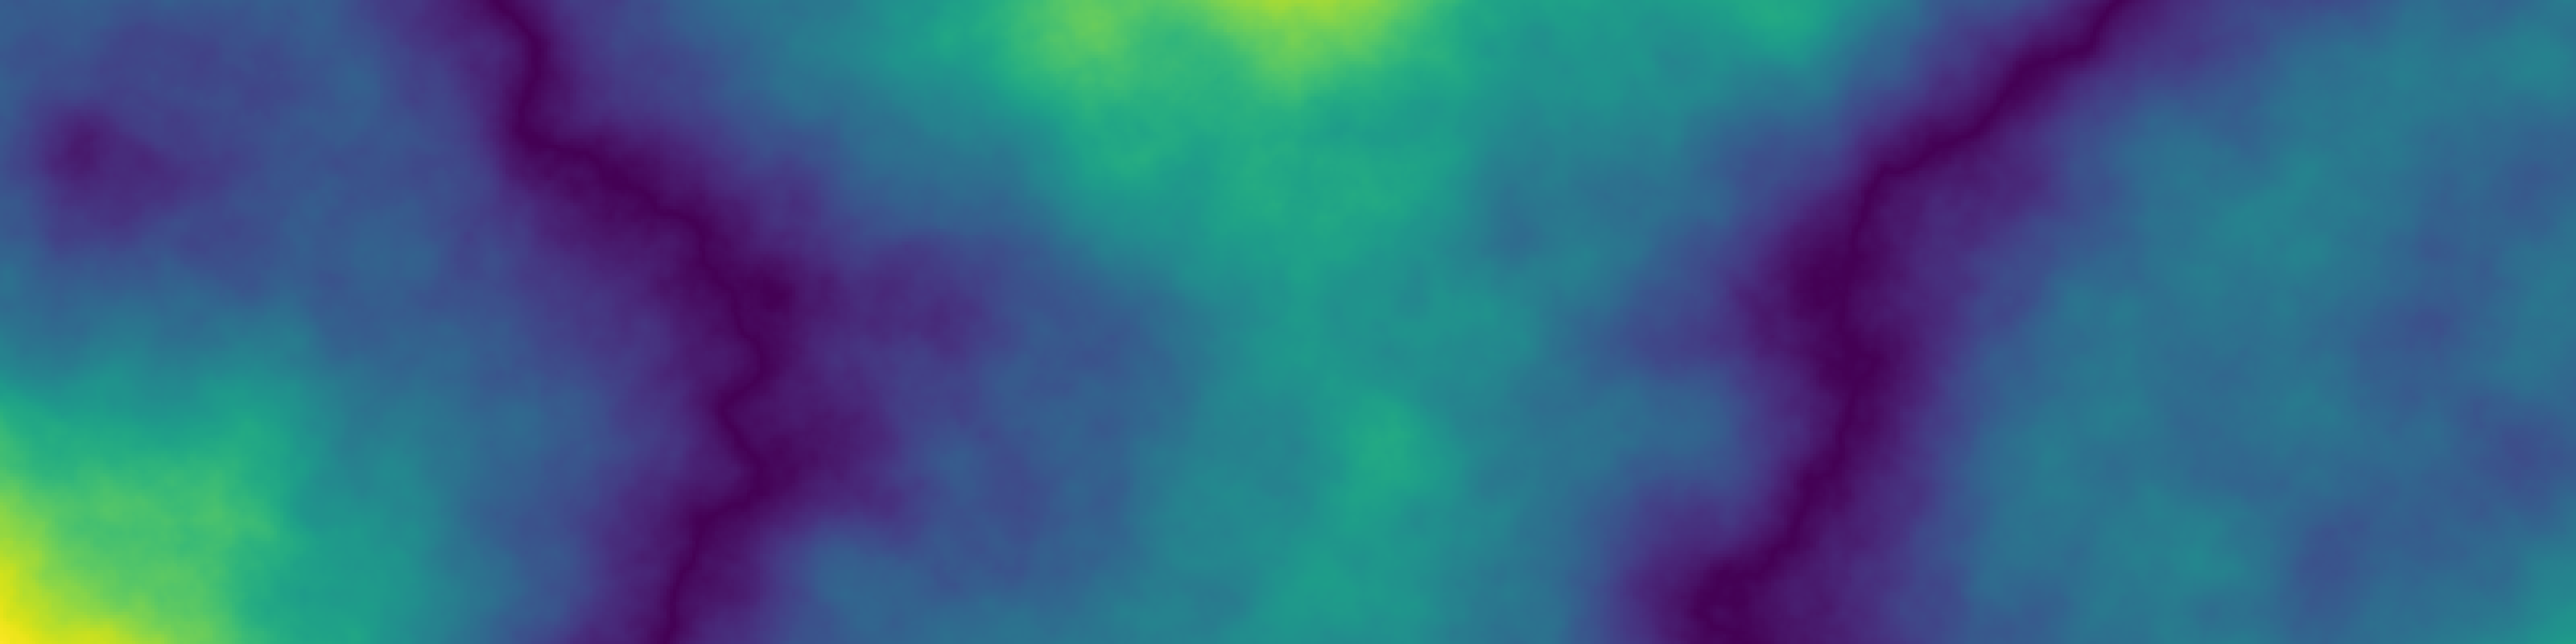

In [8]:
# Generate fractal terrain
elevation = tools.r_surf_fractal(
    output=np.array, seed=4
    )
elevation = np.abs(elevation)

# Visualize fractal terrain
m = gj.Map(width=3200)
m.d_rast(map=elevation)
m.save("basics-1.png")
m.show()

## Classify landforms

Classify landforms in the fractal terrain using [r.geomorphon](https://grass.osgeo.org/grass-stable/manuals/r.geomorphon.html).

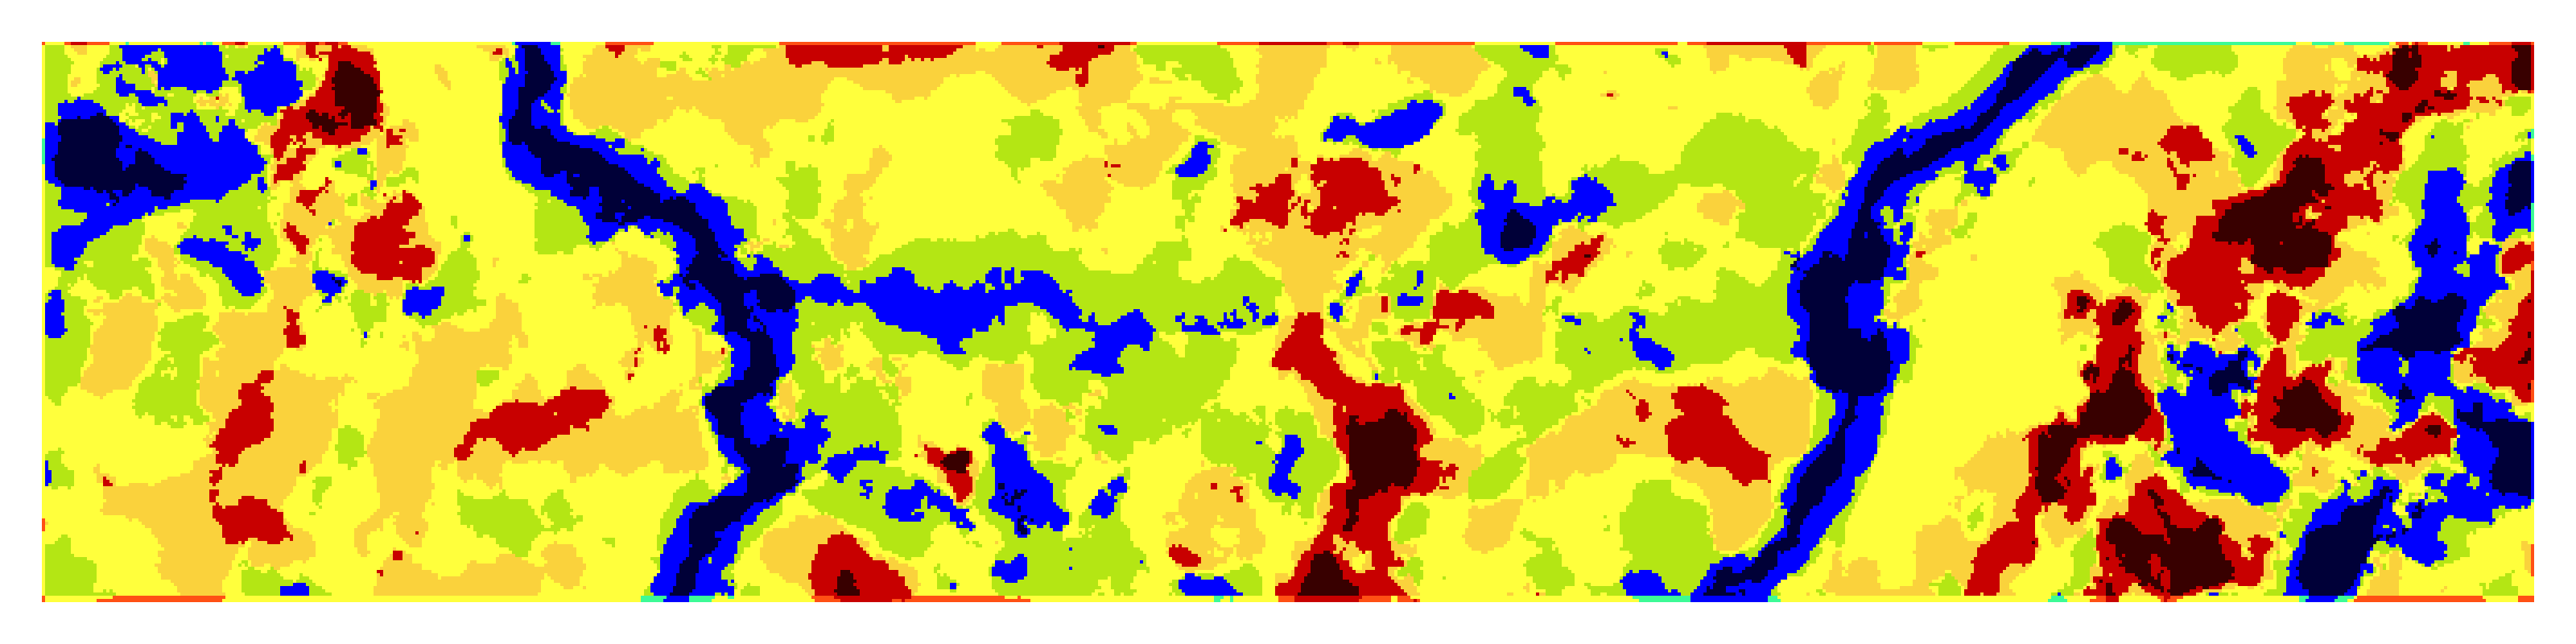

In [9]:
# Classify landforms
tools.r_geomorphon(
    elevation=elevation,
    forms="landforms",
    search=64,
    skip=12
    )

# Visualize landforms
m = gj.Map(width=3200)
m.d_rast(map="landforms")
m.save("basics-2.png")
m.show()